<a href="https://colab.research.google.com/github/Srasti05/4IK25CS203_DAV_LAB/blob/main/4IK25CS203_EXPERIENTIAL_LEARNING.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Importing Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


Load the Dataset

In [ ]:
df = pd.read_csv('/content/StudentPerformanceFactors.csv')

df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [ ]:
df.shape

(6607, 20)

Check missing values

In [ ]:
# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

Missing Values:
Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

Duplicate Records:
0


Clean the dataset

In [ ]:
# Create a copy of the dataset
cleaned_df = df.copy()

# Remove duplicate records
cleaned_df = cleaned_df.drop_duplicates()

# Fill missing numerical values with median
for col in cleaned_df.select_dtypes(include=np.number).columns:
    cleaned_df[col] = cleaned_df[col].fillna(cleaned_df[col].median())

# Fill missing categorical values with mode
for col in cleaned_df.select_dtypes(include='object').columns:
    cleaned_df[col] = cleaned_df[col].fillna(cleaned_df[col].mode()[0])

print("Data Cleaning Completed!")
print("Remaining Missing Values:", cleaned_df.isnull().sum().sum())
print("New Dataset Shape:", cleaned_df.shape)

Data Cleaning Completed!
Remaining Missing Values: 0
New Dataset Shape: (6607, 20)


Data Preprocessing

In [ ]:
# Check data types
print("Data Types:")
print(cleaned_df.dtypes)

# Convert object columns into categorical data types
for col in cleaned_df.select_dtypes(include='object').columns:
    cleaned_df[col] = cleaned_df[col].astype('category')

print("\nPreprocessing Completed!")

Data Types:
Hours_Studied                  int64
Attendance                     int64
Parental_Involvement          object
Access_to_Resources           object
Extracurricular_Activities    object
Sleep_Hours                    int64
Previous_Scores                int64
Motivation_Level              object
Internet_Access               object
Tutoring_Sessions              int64
Family_Income                 object
Teacher_Quality               object
School_Type                   object
Peer_Influence                object
Physical_Activity              int64
Learning_Disabilities         object
Parental_Education_Level      object
Distance_from_Home            object
Gender                        object
Exam_Score                     int64
dtype: object

Preprocessing Completed!


Exploratory Data Analysis (EDA)

In [ ]:
# Average examination score
print("Average Exam Score:", cleaned_df['Exam_Score'].mean())

# Highest examination score
print("Highest Exam Score:", cleaned_df['Exam_Score'].max())

# Lowest examination score
print("Lowest Exam Score:", cleaned_df['Exam_Score'].min())

# Average study hours
print("Average Study Hours:", cleaned_df['Hours_Studied'].mean())

# Average attendance
print("Average Attendance:", cleaned_df['Attendance'].mean())

Average Exam Score: 67.23565914938702
Highest Exam Score: 101
Lowest Exam Score: 55
Average Study Hours: 19.975329196306948
Average Attendance: 79.97744816104132


Visualization 1 – Study Hours vs Exam Score


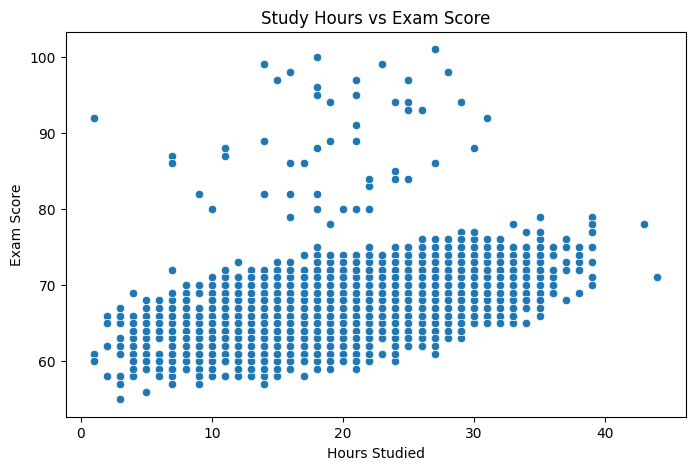

In [ ]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=cleaned_df, x='Hours_Studied', y='Exam_Score')
plt.title('Study Hours vs Exam Score')
plt.xlabel('Hours Studied')
plt.ylabel('Exam Score')
plt.show()

Visualization 2 – Attendance Distribution

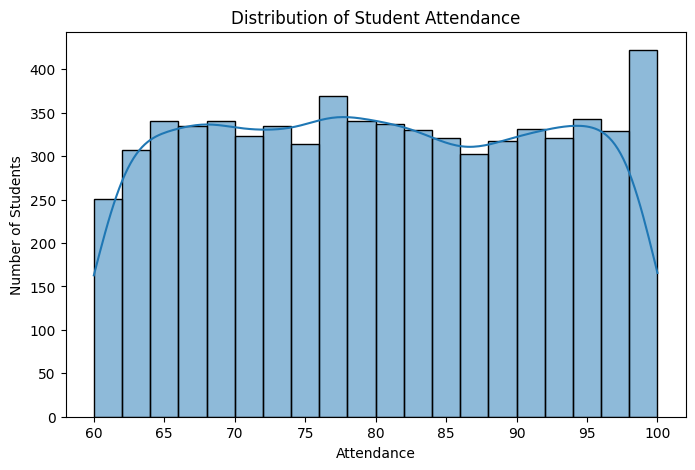

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(cleaned_df['Attendance'], bins=20, kde=True)
plt.title('Distribution of Student Attendance')
plt.xlabel('Attendance')
plt.ylabel('Number of Students')
plt.show()

Visualization 3 – Exam Score Distribution

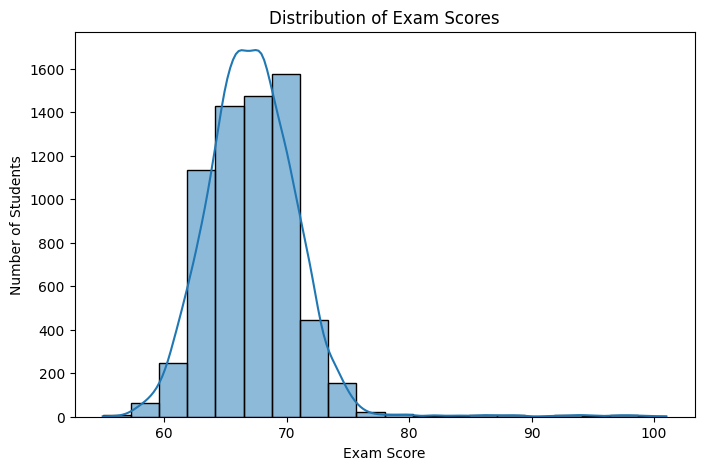

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(cleaned_df['Exam_Score'], bins=20, kde=True)
plt.title('Distribution of Exam Scores')
plt.xlabel('Exam Score')
plt.ylabel('Number of Students')
plt.show()

Visualization 4 – Parental Involvement

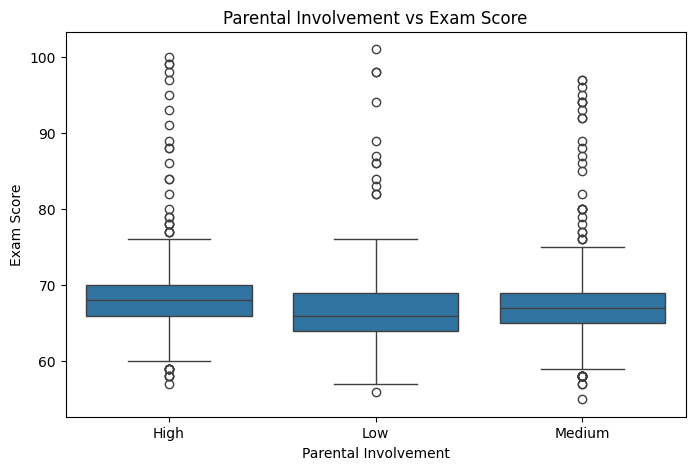

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(data=cleaned_df, x='Parental_Involvement', y='Exam_Score')
plt.title('Parental Involvement vs Exam Score')
plt.xlabel('Parental Involvement')
plt.ylabel('Exam Score')
plt.show()

Visualization 5 – Sleep Hours vs Exam Score

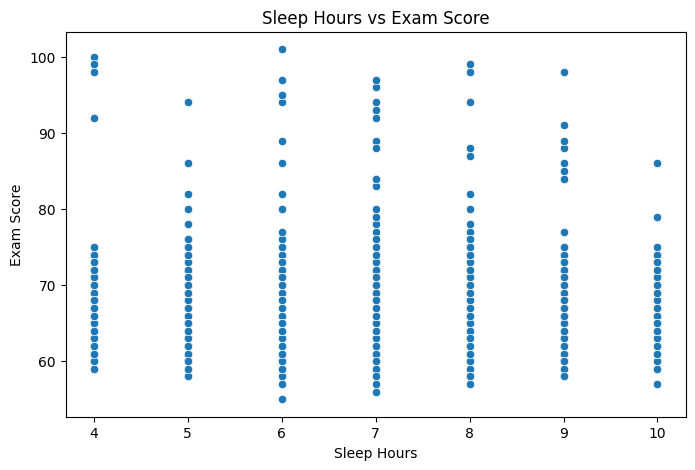

In [ ]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=cleaned_df,
    x='Sleep_Hours',
    y='Exam_Score'
)

plt.title('Sleep Hours vs Exam Score')
plt.xlabel('Sleep Hours')
plt.ylabel('Exam Score')

plt.show()

Visualization 6 – Correlation Heatmap

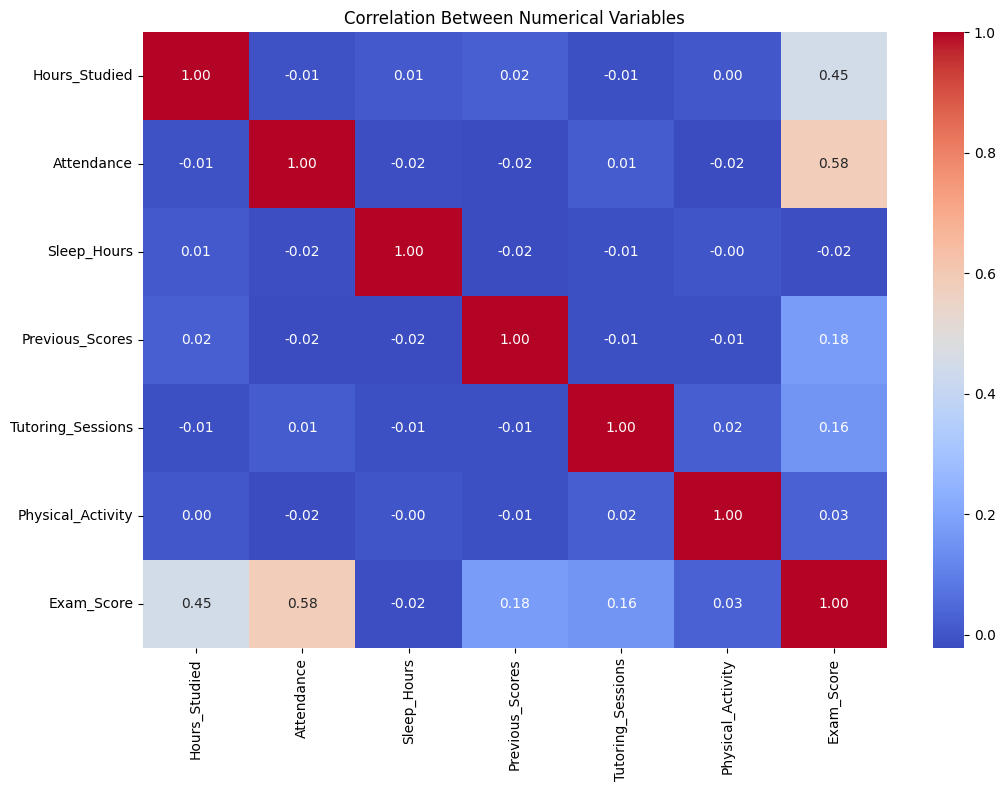

In [ ]:
plt.figure(figsize=(12,8))

numeric_df = cleaned_df.select_dtypes(include=np.number)

sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Between Numerical Variables')
plt.show()

Generate Important Insights

In [ ]:
# Important Findings

print("========== STUDENT PERFORMANCE INSIGHTS ==========")

print("\n1. Average Exam Score:")
print(cleaned_df['Exam_Score'].mean())

print("\n2. Average Study Hours:")
print(cleaned_df['Hours_Studied'].mean())

print("\n3. Average Attendance:")
print(cleaned_df['Attendance'].mean())

print("\n4. Correlation between Study Hours and Exam Score:")
print(cleaned_df['Hours_Studied'].corr(cleaned_df['Exam_Score']))

print("\n5. Correlation between Attendance and Exam Score:")
print(cleaned_df['Attendance'].corr(cleaned_df['Exam_Score']))

print("\n6. Average Exam Score by Parental Involvement:")
print(cleaned_df.groupby('Parental_Involvement', observed=True)['Exam_Score'].mean())

print("\n7. Average Exam Score by Sleep Hours:")
print(cleaned_df.groupby('Sleep_Hours')['Exam_Score'].mean())

========== STUDENT PERFORMANCE INSIGHTS ==========

1. Average Exam Score:
67.23565914938702

2. Average Study Hours:
19.975329196306948

3. Average Attendance:
79.97744816104132

4. Correlation between Study Hours and Exam Score:
0.44545495407528235

5. Correlation between Attendance and Exam Score:
0.5810718633120645

6. Average Exam Score by Parental Involvement:
Parental_Involvement
High      68.092767
Low       66.358265
Medium    67.098156
Name: Exam_Score, dtype: float64

7. Average Exam Score by Sleep Hours:
Sleep_Hours
4     67.627832
5     67.297842
6     67.194767
7     67.242964
8     67.218728
9     67.149677
10    67.137821
Name: Exam_Score, dtype: float64


Technologies Used
1. Python – Programming language.
2. Pandas – Data manipulation and analysis.
3. NumPy – Numerical operations.
4. Matplotlib – Data visualization.
5. Seaborn – Statistical visualization.
6. Google Colab – Notebook environment.